# Preprocessing + PCA on S&P 500 returns

In this notebook I take daily prices for the S&P 500 stocks and try to extract a "clean" version of each stock's return, the part that *isn't* just the market moving up or down, and the part that *isn't* just the stock's sector moving up or down. Then I run PCA on what's left to see what underlying factors are actually driving things.

I'll build two versions of the cleaned returns:

- **Q1**: for each stock, subtract its sensitivity to the market (the S&P 500). This is the classic CAPM idea: every stock has a β (beta) telling you how much it moves when the market moves, and the part of its return that *isn't* β × market is its "residual".
- **Q2**: same idea, but go one step further: instead of subtracting the market, subtract its own sector ETF (e.g. for Apple, subtract Technology Select Sector SPDR, XLK).

The plan is: build Q1, check that it works, run PCA on it, then notice that the dominant remaining factor is "energy stocks all move together", and build Q2 to strip that out too. Finally I compare Q1 and Q2 side by side.

The dataset is monthly-rebalanced S&P 500 history from 2000 through early 2026, with delisted historical members kept in the database (so I'm not introducing survivorship bias).


## 1. Setup

Imports and the connection to the ArcticDB I'm using as the data store. The four libraries I'll touch are:

- `stocks_lib`: current S&P 500 members' price history
- `removed_stocks`: historical members that have since been removed (kept to avoid survivorship bias)
- `etfs_lib`: sector ETFs + SPY
- `metadata_lib`: the S&P 500 membership intervals (when each ticker entered / left the index)


In [1]:
import pandas as pd
import numpy as np
import arcticdb as adb
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from matplotlib.patches import Patch
from collections import Counter, defaultdict


In [1]:
START = "2000-01-01"
END   = "2026-02-15"
ARCTIC_URI = "lmdb://./database/arctic"

ac = adb.Arctic(ARCTIC_URI)
etf_lib     = ac["etfs_lib"]
stocks_lib  = ac["stocks_lib"]
removed_lib = ac["removed_stocks"]


LibraryNotFound: etfs_lib

### Ticker → sector lookup

I want a fast `{ticker: sector}` dict that I can reuse everywhere downstream (in plots, in PC interpretation, in the Q2 build). I walk both `stocks_lib` and `removed_lib` because the historical (now-removed) members also need their sectors so I can color them in plots.


In [2]:
ticker_sector = {}
for lib in (stocks_lib, removed_lib):
    for sym in lib.list_symbols():
        meta = lib.read_metadata(sym).metadata or {}
        ticker_sector[sym] = meta.get("sector", "?")

print(f"ticker_sector built: {len(ticker_sector)} entries across "
      f"{len(set(ticker_sector.values()))} distinct sector labels")


ticker_sector built: 1084 entries across 11 distinct sector labels


## 2. First look at the data

Just confirming the database has roughly what I expect: ~500 current S&P names + a few hundred historical removals + 12 ETFs. If any of these counts looks off, something went wrong in the data fetch (which I did in a separate notebook).


In [3]:
print(f"current S&P stocks: {len(stocks_lib.list_symbols())}")
print(f"historical (removed) stocks: {len(removed_lib.list_symbols())}")
print(f"ETFs: {sorted(etf_lib.list_symbols())}")


current S&P stocks: 488
historical (removed) stocks: 596
ETFs: ['SPY', 'XLB', 'XLC', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLRE', 'XLU', 'XLV', 'XLY']


### Looking at one stock as an example

Each ticker has both a price table (the `data`) and a metadata dict (sector, industry, etc.). Let me look at META's price data to see what columns we have to work with.


In [4]:
aapl_meta = stocks_lib.read("AAPL").metadata
print("AAPL metadata:", aapl_meta)

meta_prices = stocks_lib.read("META").data
meta_prices.head()


AAPL metadata: {'permaticker': 199059, 'sector': 'Technology', 'firstpricedate': Timestamp('1986-01-01 00:00:00'), 'lastpricedate': Timestamp('2026-05-15 00:00:00'), 'industry': 'Consumer Electronics'}


,open,high,low,close,volume,closeadj,closeunadj,lastupdated
date,,,,,,,,
2012-05-18,42.05,45.00,38.00,38.23,573576000.0,37.935,38.23,2026-03-16
2012-05-21,36.53,36.66,33.00,34.03,168193000.0,33.768,34.03,2026-03-16
2012-05-22,32.61,33.59,30.94,31.00,101787000.0,30.761,31.00,2026-03-16
2012-05-23,31.37,32.50,31.36,32.00,73600000.0,31.753,32.00,2026-03-16
2012-05-24,32.95,33.21,31.77,33.03,50237000.0,32.775,33.03,2026-03-16


### What about a stock that got delisted?

`removed_lib` has the names that were once in the S&P 500 but have since been removed (acquired, went bankrupt, etc.). American Airlines (AAL) is a good example, let me check it has data.


In [5]:
aal = removed_lib.read("AAL").data
aal.head()


,open,high,low,close,volume,closeadj,closeunadj,lastupdated
date,,,,,,,,
2013-12-09,23.95,25.44,23.45,24.60,115810456.0,23.188,24.60,2020-07-16
2013-12-10,24.54,25.17,24.41,24.88,18660600.0,23.452,24.88,2020-07-16
2013-12-11,25.44,27.20,25.37,25.99,38843400.0,24.498,25.99,2020-07-16
2013-12-12,26.20,26.71,25.45,25.45,19981800.0,23.989,25.45,2020-07-16
2013-12-13,25.61,26.30,25.52,26.23,12189900.0,24.724,26.23,2020-07-16


## 3. A few helper functions I'll use a lot

These are small utilities I'll reuse throughout the notebook. Putting them up front keeps the rest of the code cleaner.


**`group_lib`**: group all tickers in a library by some metadata field. I use it to bucket tickers by GICS sector for plot coloring.


In [6]:
def group_lib(lib, key):
    buckets = defaultdict(list)
    for sym in lib.list_symbols():
        meta = lib.read_metadata(sym).metadata
        buckets[meta.get(key)].append(sym)
    return dict(buckets)


by_sector = group_lib(stocks_lib, "sector")
print(f"{len(by_sector)} sector buckets; sample sizes:")
for s, members in sorted(by_sector.items(), key=lambda kv: -len(kv[1]))[:5]:
    print(f"  {s}: {len(members)}")


11 sector buckets; sample sizes:
  Technology: 77
  Industrials: 75
  Financial Services: 69
  Healthcare: 59
  Consumer Cyclical: 47


**`check_price_records`**: for every ticker in a library, what's the earliest and latest date with valid data, and how many rows total? Useful for spotting tickers that joined the index recently (post-2000 IPOs) or have data quality issues.


In [7]:
def check_price_records(lib):
    records = []
    for item in lib.read_batch(lib.list_symbols()):
        df = item.data
        if df.empty:
            records.append((item.symbol, None, None, 0))
            continue
        records.append((item.symbol, df.index.min(), df.index.max(), len(df)))
    cov = pd.DataFrame(records, columns=["ticker", "start", "end", "count"])
    cov["start"] = pd.to_datetime(cov["start"])
    cov["end"]   = pd.to_datetime(cov["end"])
    return cov


cov = check_price_records(stocks_lib)
print(f"empty tickers: {(cov['count'] == 0).sum()}")
print(f"post-2000 IPOs (no data before 2000): {(cov['start'] > '2000-01-01').sum()}")
cov[cov["start"] > "2000-01-01"].head(10)


empty tickers: 0
post-2000 IPOs (no data before 2000): 488


,ticker,start,end,count
0,HUM,2000-01-03,2026-02-13,6569
1,AMGN,2000-01-03,2026-02-13,6569
2,MS,2000-01-03,2026-02-13,6569
3,GL,2000-01-03,2026-02-13,6569
4,FTV,2016-07-05,2026-02-13,2418
5,GDDY,2015-04-01,2026-02-13,2735
6,UNP,2000-01-03,2026-02-13,6569
7,SNPS,2000-01-03,2026-02-13,6569
8,WST,2000-01-03,2026-02-13,6569
9,DVA,2000-01-03,2026-02-13,6569


## 4. S&P 500 membership history

The S&P 500 changes over time, companies get added, removed, merged, etc. For each ticker, I have intervals telling me when it was actually an index member. I need this for two reasons:

1. **Avoiding survivorship bias.** If I just kept currently-in-the-S&P stocks, I'd be analyzing the "survivors" only, which makes any historical analysis look way too good. Instead, I keep all stocks but *mask* them outside their membership intervals.
2. **Spot-checks.** A famous case: Lehman Brothers was in the index right up until its bankruptcy in mid-September 2008. If my membership logic is right, LEHMQ should be a member on Sept 1, 2008 but not on Oct 1, 2008. I'll check this below.


In [8]:
intervals = ac["metadata_lib"].read("sp500_membership").data
intervals.head()


,ticker,start,end,permaticker
0,A,2000-06-05,NaT,196290.0
1,AAL,2015-03-17,2024-09-23,199960.0
2,AAMRQ,1957-03-04,2003-03-14,631666.0
3,AAP,2015-07-07,2023-08-25,195735.0
4,AAPL,1982-11-30,NaT,199059.0


### Two helpers around the intervals

- `members_count_on(date)`: how many tickers were in the index on a given date?
- `member_tickers_on(date)`: the actual list of tickers.


In [9]:
def members_count_on(intervals, date):
    d = pd.Timestamp(date)
    in_range = (intervals["start"].fillna(pd.Timestamp.min) <= d) & \
               (intervals["end"].fillna(pd.Timestamp.max) >= d)
    return intervals.loc[in_range, "permaticker"].nunique()


def member_tickers_on(intervals, date):
    d = pd.Timestamp(date)
    in_range = (intervals["start"].fillna(pd.Timestamp.min) <= d) & \
               (intervals["end"].fillna(pd.Timestamp.max) >= d)
    return intervals.loc[in_range, "ticker"].dropna().unique().tolist()


# Quick sanity check — member count by year. Should be ~500 every year.
for year in range(2000, 2027, 5):
    print(f"  {year}-06-30: {members_count_on(intervals, f'{year}-06-30')} members")


  2000-06-30: 500 members
  2005-06-30: 500 members
  2010-06-30: 501 members
  2015-06-30: 504 members
  2020-06-30: 505 members
  2025-06-30: 503 members


### Visualizing member count over time

The official count is 500, but in practice it can be slightly off (498-510) because of timing, for a day or two during a transition there can be one extra or one fewer name. I'm plotting the count on June 30 of each year to confirm it stays in that range.


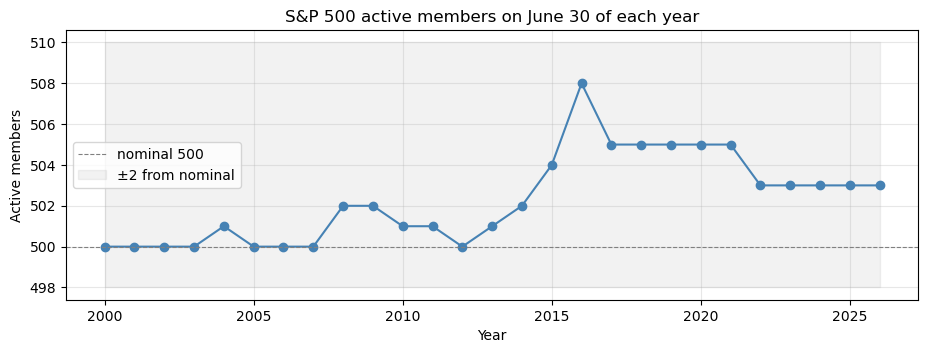

In [10]:
years = list(range(2000, 2027))
counts = [members_count_on(intervals, f"{y}-06-30") for y in years]

plt.figure(figsize=(11, 3.5))
plt.plot(years, counts, marker="o", color="steelblue")
plt.axhline(500, color="gray", lw=0.8, ls="--", label="nominal 500")
plt.fill_between(years, 498, 510, color="gray", alpha=0.10, label="±2 from nominal")
plt.title("S&P 500 active members on June 30 of each year")
plt.xlabel("Year"); plt.ylabel("Active members")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


### Sanity check 2: count by ticker and by permaticker should match

`permaticker` is a unique numeric ID that doesn't change even if the company's ticker symbol changes (e.g. FB → META). If `ticker` count and `permaticker` count match, I know I don't have any duplicate listings of the same company on a given date.


In [11]:
def detail_on(intervals, date):
    d = pd.Timestamp(date)
    in_range = (intervals["start"].fillna(pd.Timestamp.min) <= d) & \
               (intervals["end"].fillna(pd.Timestamp.max) >= d)
    sub = intervals.loc[in_range]
    return sub["ticker"].nunique(), sub["permaticker"].nunique()


print(f"  2016-06-30 → (tickers, permatickers) = {detail_on(intervals, '2016-06-30')}  (expect equal)")
print(f"  2026-05-15 → (tickers, permatickers) = {detail_on(intervals, '2026-05-15')}  (expect equal)")


  2016-06-30 → (tickers, permatickers) = (508, 508)  (expect equal)
  2026-05-15 → (tickers, permatickers) = (503, 503)  (expect equal)


### The Lehman spot-check

Lehman Brothers filed for bankruptcy on Sept 15, 2008. Sharadar codes the ticker as `LEHMQ` (the `Q` suffix is the post-bankruptcy OTC quote). The membership intervals should show:

- Member on 2008-09-01 ✔
- Not a member on 2008-10-01 ✔
- Still present in `removed_lib` with price history that ends shortly after the bankruptcy ✔

If all three pass, I trust the point-in-time membership logic.


In [12]:
print("LEHMQ in member_tickers_on(2008-09-01)?",
      "LEHMQ" in member_tickers_on(intervals, "2008-09-01"))
print("LEHMQ in member_tickers_on(2008-10-01)?",
      "LEHMQ" in member_tickers_on(intervals, "2008-10-01"))
print("LEHMQ in removed_lib?",
      "LEHMQ" in removed_lib.list_symbols())
if "LEHMQ" in removed_lib.list_symbols():
    leh = removed_lib.read("LEHMQ").data
    print(f"LEHMQ price history: {leh.index.min().date()} → {leh.index.max().date()}  ({len(leh)} rows)")


LEHMQ in member_tickers_on(2008-09-01)? True
LEHMQ in member_tickers_on(2008-10-01)? False
LEHMQ in removed_lib? True
LEHMQ price history: 2000-01-03 → 2008-10-15  (2210 rows)


### Checking the sector + market benchmarks

For Q1 I need SPY (S&P 500 ETF) as the market proxy. For Q2 I need each of the 11 GICS sector ETFs (XLK, XLF, XLV, XLE, XLI, XLY, XLP, XLB, XLU, XLRE, XLC). All should be in `etfs_lib`.


In [13]:
sector_etfs = ["XLK", "XLF", "XLV", "XLE", "XLI", "XLY", "XLP", "XLB", "XLU", "XLRE", "XLC", "SPY"]
for t in sector_etfs:
    print(f"  {t}: {'exists' if t in etf_lib.list_symbols() else 'MISSING'}")


  XLK: exists
  XLF: exists
  XLV: exists
  XLE: exists
  XLI: exists
  XLY: exists
  XLP: exists
  XLB: exists
  XLU: exists
  XLRE: exists
  XLC: exists
  SPY: exists


## 5. Building the wide price panel

I'm going to convert the per-ticker price tables into one big `(dates × tickers)` DataFrame. This is the canonical thing I'll do residualization and PCA on. Two pieces I need:

1. `membership_mask`: a boolean DataFrame, same shape as the prices, that's True only where the ticker was actually an index member. I'll use this to mask out prices outside membership intervals.
2. `build_price_panel`: stack the `closeadj` column from `stocks_lib` and `removed_lib` into one wide frame, then apply the mask.

After this step, `prices` is `(6569 × ~1100)`: about 6,500 trading days and around 1,100 distinct tickers (current + historical members).


In [14]:
def membership_mask(intervals, dates, tickers):
    """Boolean DataFrame: True where ticker was in the S&P 500 on that date."""
    tickers = pd.Index(tickers)
    mask = pd.DataFrame(False, index=dates, columns=tickers)
    relevant = intervals[intervals["ticker"].isin(tickers)]
    for _, row in relevant.iterrows():
        t = row["ticker"]
        start = row["start"] if pd.notna(row["start"]) else dates.min()
        end   = row["end"]   if pd.notna(row["end"])   else dates.max()
        in_win = (dates >= start) & (dates <= end)
        mask.loc[in_win, t] = True
    return mask


def build_price_panel(stocks_lib, removed_lib, intervals=None, field="closeadj"):
    series = []
    for lib in (stocks_lib, removed_lib):
        for item in lib.read_batch(lib.list_symbols()):
            if field not in item.data.columns or item.data[field].isna().all():
                continue
            series.append(item.data[field].rename(item.symbol))
    prices = pd.concat(series, axis=1).sort_index()
    if intervals is not None:
        mask = membership_mask(intervals, prices.index, prices.columns)
        prices = prices.where(mask)
    return prices


## 6. First attempt at Q1, just subtract the market (β = 1)

The simplest possible "market-residual return" is just `r_i - r_SPY`. This assumes every stock has β = 1, which is wrong in general but useful as a sanity check first. Once this works, I'll upgrade to a real rolling β.

Below I build the price panel, pull SPY as the benchmark, compute the simple residual, and run a few quick checks: shape should be `(trading_days, ~1100 tickers)`, median tickers per row should be ~500 (matching the index size), and the COVID dip day 2020-03-16 should show broad negative dispersion.


In [15]:
def build_market_residual_returns(prices, benchmark_prices):
    log_ret = np.log(prices / prices.shift(1))
    bench_ret = np.log(benchmark_prices / benchmark_prices.shift(1))
    return log_ret.sub(bench_ret.reindex(log_ret.index), axis=0)


# Build the price panel and the simple market residual
prices = build_price_panel(stocks_lib, removed_lib, intervals=intervals)
spy = etf_lib.read("SPY").data["closeadj"]
returns_market_residual = build_market_residual_returns(prices, spy)

print(f"shape: {returns_market_residual.shape}")
print(f"median non-null tickers per row: "
      f"{returns_market_residual.notna().sum(axis=1).median():.0f}  (expect ~500)")
print("\n2020-03-16 (COVID dip) describe:")
print(returns_market_residual.loc["2020-03-16"].describe())


shape: (6569, 1084)
median non-null tickers per row: 500  (expect ~500)

2020-03-16 (COVID dip) describe:
count    505.000000
mean      -0.022235
std        0.070809
min       -0.293734
25%       -0.063809
50%       -0.018832
75%        0.025673
max        0.222506
Name: 2020-03-16 00:00:00, dtype: float64


### Side-checking the Lehman case in the price panel

Above I confirmed the membership intervals correctly flag LEHMQ as removed after September 2008. Now I check that the price panel actually honors that: LEHMQ should have non-NaN prices in early September 2008 but **all-NaN** from October onward.


In [16]:
if "LEHMQ" in prices.columns:
    leh_col = prices["LEHMQ"]
    fv, lv = leh_col.first_valid_index(), leh_col.last_valid_index()
    print(f"LEHMQ in prices panel: {fv.date()} → {lv.date()}")
    print(f"  2008-09-01 → 2008-09-19 non-null: "
          f"{leh_col.loc['2008-09-01':'2008-09-19'].notna().sum()} days")
    print(f"  2008-10-01 → 2008-10-31 non-null: "
          f"{leh_col.loc['2008-10-01':'2008-10-31'].notna().sum()} days  (should be 0)")
else:
    print("LEHMQ not in prices panel — unexpected")


LEHMQ in prices panel: 2000-01-03 → 2008-09-22
  2008-09-01 → 2008-09-19 non-null: 14 days
  2008-10-01 → 2008-10-31 non-null: 0 days  (should be 0)


### What does "subtract the market" look like?

For four sample stocks across different sectors I plot two lines:

- **Blue** = the raw cumulative log return for 2018-2019
- **Orange** = the *market-residual* cumulative return (raw minus SPY)

If the residualization is doing its job, the orange line should be much flatter than the blue line, it's just the part of each stock's behavior that *isn't* explained by the market moving.


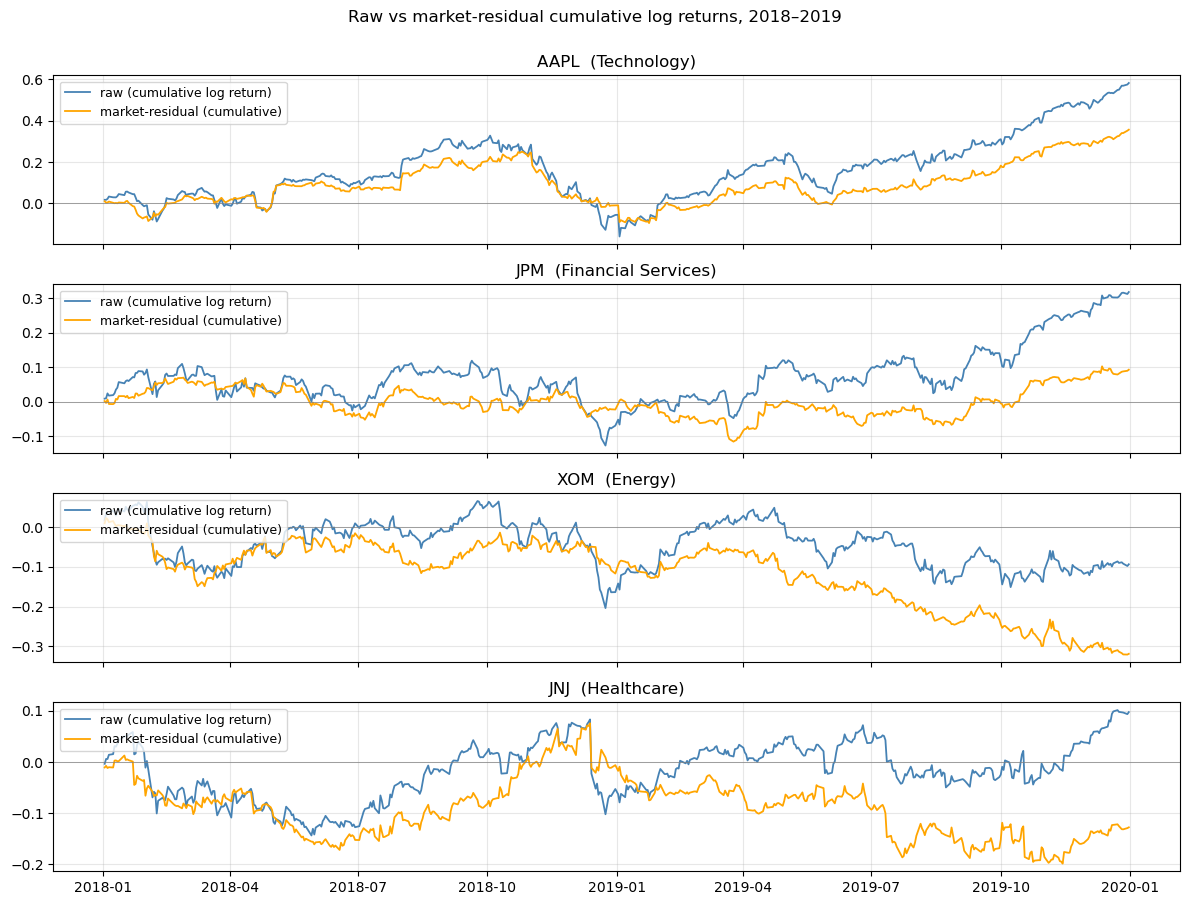

In [17]:
example_tickers = ["AAPL", "JPM", "XOM", "JNJ"]
log_ret_panel = np.log(prices / prices.shift(1))
window = slice("2018", "2019")

fig, axes = plt.subplots(len(example_tickers), 1, figsize=(12, 9), sharex=True)
for ax, t in zip(axes, example_tickers):
    raw = log_ret_panel.loc[window, t].cumsum()
    resid = returns_market_residual.loc[window, t].cumsum()
    ax.plot(raw.index, raw, label="raw (cumulative log return)", color="steelblue", lw=1.3)
    ax.plot(resid.index, resid, label="market-residual (cumulative)", color="orange", lw=1.3)
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_title(f"{t}  ({ticker_sector.get(t, '?')})")
    ax.legend(loc="upper left", fontsize=9); ax.grid(alpha=0.3)
fig.suptitle("Raw vs market-residual cumulative log returns, 2018–2019", y=1.00)
fig.tight_layout()
plt.show()


## 7. The real Q1: rolling 252-day β instead of β = 1

The β = 1 assumption is too crude, utilities have β around 0.5, tech stocks often have β around 1.3 or higher. The real CAPM-residual uses a *rolling β*:

```
β_i,t = Cov(r_i, r_SPY) / Var(r_SPY)   over the last 252 trading days
residual_i,t = r_i,t  −  β_i,t · r_SPY,t
```

One subtle but critical thing: the β used for day `t` must come from data through day `t-1`, not data including day `t`. Otherwise the residual "knows the future" and the analysis is invalid (look-ahead bias). I enforce this with `.shift(1)` on the β series.


In [ ]:
def build_capm_residual_returns(prices, benchmark_prices, window=252):
    log_ret = np.log(prices / prices.shift(1))
    bench_ret = np.log(benchmark_prices / benchmark_prices.shift(1)).reindex(log_ret.index)
    cov  = log_ret.rolling(window).cov(bench_ret)
    var  = bench_ret.rolling(window).var()
    beta = cov.div(var, axis=0).shift(1)             # shift(1) → no look-ahead
    return log_ret - beta.mul(bench_ret, axis=0)


### Does the residualization actually work?

If Q1 successfully removes the market signal, then **PC1 of Q1 should be uncorrelated with SPY**. Why? PC1 is the direction of maximum variance, and if there's no market signal left, PC1 picks up the *next*-largest source of co-movement, which won't be the market.

I'll test this on the 2018-2019 window first, then in the next cell check whether it holds for *every* year.


In [19]:
returns_capm_residual = build_capm_residual_returns(prices, spy)

# Some tickers appear in both stocks_lib and removed_lib (AMD/FSLR/JBL/...) → duplicate columns.
# Dedup before any PCA work.
sample = returns_capm_residual.loc["2018":"2019"]
sample = sample.loc[:, ~sample.columns.duplicated()]
sample = sample.dropna(axis=1).fillna(0)

pc1 = PCA(n_components=1).fit_transform(sample)
spy_ret_18_19 = np.log(spy / spy.shift(1)).loc[sample.index]
print(f"corr(PC1, SPY) = {np.corrcoef(pc1.flatten(), spy_ret_18_19)[0,1]:.3f}  "
      f"(expect ≈ 0 if residualization worked)")


corr(PC1, SPY) = 0.058  (expect ≈ 0 if residualization worked)


### How β actually moves and what the residual looks like

Two-panel plot for the same four sample stocks:

- **Top**: the rolling 252-day β for each stock vs SPY. Note JPM drifting up post-2020, XOM spiking during the 2020 oil collapse, AAPL hovering in the 1.0-1.4 band.
- **Bottom**: the cumulative CAPM-residual log return. This is the "what's left after stripping out the market" version of each stock's behavior.


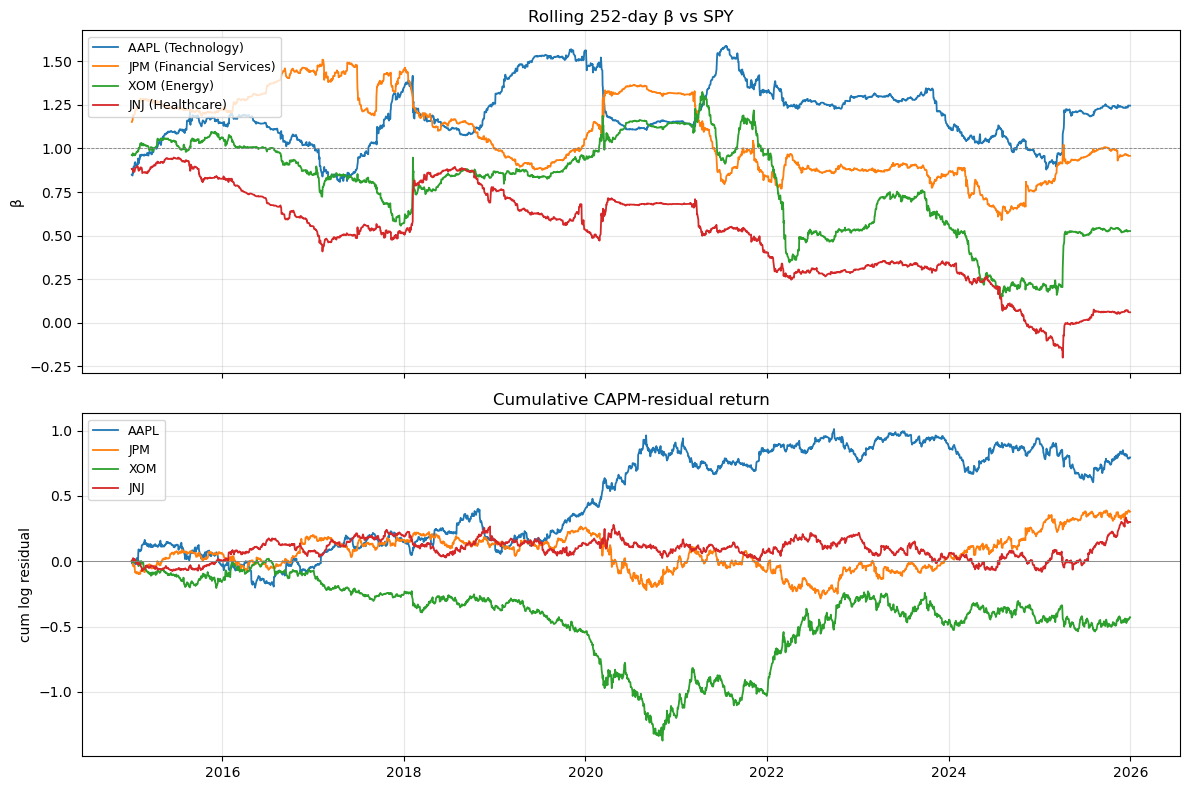

In [20]:
spy_ret = np.log(spy / spy.shift(1))
window = slice("2015", "2025")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for t in example_tickers:
    cov = log_ret_panel[t].rolling(252).cov(spy_ret)
    var = spy_ret.rolling(252).var()
    beta = (cov / var).shift(1).loc[window]
    axes[0].plot(beta.index, beta, label=f"{t} ({ticker_sector.get(t, '?')})", lw=1.3)
axes[0].axhline(1.0, color="gray", lw=0.6, ls="--")
axes[0].set_title("Rolling 252-day β vs SPY")
axes[0].set_ylabel("β"); axes[0].legend(loc="upper left", fontsize=9)
axes[0].grid(alpha=0.3)

for t in example_tickers:
    cum = returns_capm_residual.loc[window, t].cumsum()
    axes[1].plot(cum.index, cum, label=t, lw=1.3)
axes[1].axhline(0, color="gray", lw=0.6)
axes[1].set_title("Cumulative CAPM-residual return")
axes[1].set_ylabel("cum log residual"); axes[1].legend(loc="upper left", fontsize=9)
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()


### Does the residualization hold across *all* years?

The static 2018-2019 test gave `corr(PC1, SPY) ≈ 0`, which is good. But I want to know whether it's that small in *every* year, or whether 2018-2019 was a lucky window. So I redo the test on rolling 1-year windows (stepped every 6 months) and plot the correlation over time.

A green band marks the ±0.10 zone, anything inside that band is "basically zero". I expect occasional spikes during stressed regimes (GFC, COVID, 2022 rates) because in those periods β is moving fast and a fixed 252-day β can't keep up.


46 rolling windows; mean corr = +0.027, min = -0.399, max = +0.564
|corr| > 0.10 in 27 of 46 windows


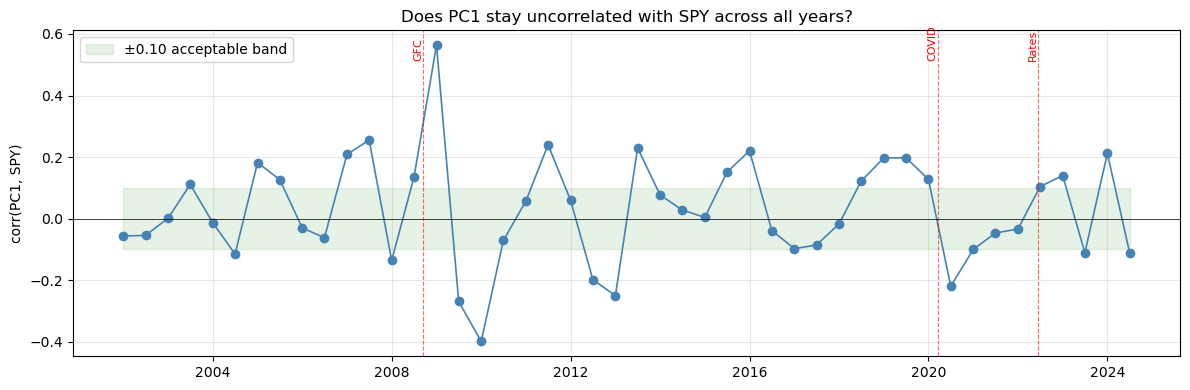

In [21]:
windows = pd.date_range("2002-01-01", "2024-07-01", freq="6MS")
q1_rolling = []
for w_start in windows:
    w_end = w_start + pd.DateOffset(years=1)
    sub = returns_capm_residual.loc[w_start:w_end]
    sub = sub.loc[:, ~sub.columns.duplicated()].dropna(axis=1, thresh=200).fillna(0)
    if sub.shape[1] < 50:
        continue
    pc1 = PCA(n_components=1).fit_transform(sub).flatten()
    spy_w = np.log(spy / spy.shift(1)).reindex(sub.index)
    valid = spy_w.notna()
    corr = np.corrcoef(pc1[valid], spy_w[valid])[0, 1]
    q1_rolling.append({"window_start": w_start, "corr_pc1_spy": corr,
                        "n_stocks": sub.shape[1]})

q1_rolling = pd.DataFrame(q1_rolling)
print(f"{len(q1_rolling)} rolling windows; "
      f"mean corr = {q1_rolling['corr_pc1_spy'].mean():+.3f}, "
      f"min = {q1_rolling['corr_pc1_spy'].min():+.3f}, "
      f"max = {q1_rolling['corr_pc1_spy'].max():+.3f}")
print(f"|corr| > 0.10 in {(q1_rolling['corr_pc1_spy'].abs() > 0.10).sum()} of {len(q1_rolling)} windows")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(q1_rolling["window_start"], q1_rolling["corr_pc1_spy"],
        marker="o", lw=1.2, color="steelblue")
ax.axhline(0, color="black", lw=0.5)
ax.fill_between(q1_rolling["window_start"], -0.10, 0.10,
                color="green", alpha=0.10, label="±0.10 acceptable band")
for label, x in [("GFC", "2008-09-15"), ("COVID", "2020-03-15"), ("Rates", "2022-06-15")]:
    ax.axvline(pd.Timestamp(x), color="red", ls="--", lw=0.8, alpha=0.6)
    ax.text(pd.Timestamp(x), ax.get_ylim()[1] * 0.85, label,
            rotation=90, fontsize=8, color="red", ha="right")
ax.set_title("Does PC1 stay uncorrelated with SPY across all years?")
ax.set_ylabel("corr(PC1, SPY)"); ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


**What this tells me.** The 2018-2019 result (≈ 0.06) is actually one of the *best* windows. Most of the time the correlation hovers in the −0.4 to +0.5 range, with the worst spike during the 2008 GFC. So fixed-252-day β does an okay job *on average* but the residual still picks up some market signal in stressed regimes. For the downstream analysis I'll keep this in mind, Q1 is "mostly market-stripped" but not perfectly so.


## 8. Now run PCA on Q1, but how many factors are real?

PCA will always give me factors, even from pure noise. So the question isn't "what does PCA tell me?", it's "how many of the components PCA gave me are actually signal vs noise?"

There's a beautiful answer from random matrix theory: **Marchenko-Pastur (1967)**. If I have an N×T matrix of pure-noise returns (with N stocks and T trading days), the eigenvalues of the correlation matrix follow a known distribution with a sharp upper edge:

```
λ_+ = (1 + √(N/T))²
```

If I express that as an explained-variance ratio (divide by N), I get a "noise floor", any PC above it is too large to be explained by chance, and is therefore real signal. Anything below it is noise.

For my 2018-2019 sample (N ≈ 500 stocks, T ≈ 500 days), N/T ≈ 1.0 and the noise floor sits at roughly 0.012 (1.2% of total variance). So a PC has to explain more than 1.2% to count as real.


In [22]:
pca_full = PCA(n_components=50).fit(sample)
ratios = pca_full.explained_variance_ratio_

T, N = sample.shape
mp_floor = ((1 + np.sqrt(N / T)) ** 2) / N

print(f"N={N} stocks, T={T} days, N/T={N/T:.3f}")
print(f"MP noise floor (explained variance ratio): {mp_floor:.4f}")
print(f"PCs above MP floor: {(ratios > mp_floor).sum()} of 50\n")

pc_table = pd.DataFrame({
    "PC": np.arange(1, 51),
    "explained_var": ratios.round(4),
    "above_MP": ratios > mp_floor,
})
print(pc_table.head(25).to_string(index=False))


N=433 stocks, T=503 days, N/T=0.861
MP noise floor (explained variance ratio): 0.0086
PCs above MP floor: 22 of 50

 PC  explained_var  above_MP
  1         0.0836      True
  2         0.0455      True
  3         0.0380      True
  4         0.0287      True
  5         0.0259      True
  6         0.0205      True
  7         0.0176      True
  8         0.0154      True
  9         0.0150      True
 10         0.0138      True
 11         0.0125      True
 12         0.0121      True
 13         0.0115      True
 14         0.0107      True
 15         0.0103      True
 16         0.0101      True
 17         0.0099      True
 18         0.0098      True
 19         0.0092      True
 20         0.0090      True
 21         0.0089      True
 22         0.0086      True
 23         0.0085     False
 24         0.0081     False
 25         0.0079     False


### Visualizing the cutoff

Bar chart of all 50 PCs, with blue bars for the ones above the noise floor (= signal) and gray for the ones below (= noise). The red dashed line is the MP cutoff. You can literally see where signal ends and noise begins.


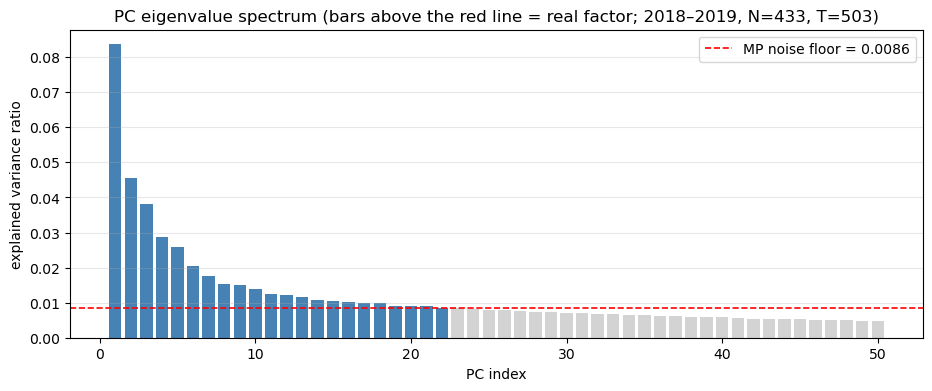

In [23]:
colors_bar = ["steelblue" if r > mp_floor else "lightgray" for r in ratios]
plt.figure(figsize=(11, 4))
plt.bar(range(1, 51), ratios, color=colors_bar)
plt.axhline(mp_floor, color="red", lw=1.2, ls="--",
           label=f"MP noise floor = {mp_floor:.4f}")
plt.title(f"PC eigenvalue spectrum (bars above the red line = real factor; 2018–2019, N={N}, T={T})")
plt.xlabel("PC index"); plt.ylabel("explained variance ratio")
plt.legend(); plt.grid(alpha=0.3, axis="y")
plt.show()


### What are the surviving PCs actually *about*?

If PC1 has weights mostly on Energy stocks, it's an "energy factor". If PC2 has positive weights on Tech and negative on Utilities, it's a "growth vs defensive" factor. Let me look at the top 10 loaders (highest |weight|) for each of the top 5 PCs, and check their GICS sectors.


In [24]:
pca = PCA(n_components=10).fit(sample)
loadings = pd.DataFrame(
    pca.components_[:5].T,
    index=sample.columns,
    columns=[f"PC{i+1}" for i in range(5)],
)

for pc in loadings.columns:
    top = loadings[pc].abs().nlargest(10).index
    print(f"\n{pc} top loaders:")
    for t in top:
        sign = "+" if loadings.loc[t, pc] > 0 else "-"
        print(f"  {sign} {t:<8} {ticker_sector.get(t, '?')}")



PC1 top loaders:
  + APA      Energy
  + XEC      Energy
  + NBL      Energy
  + DVN      Energy
  + CXO      Energy
  + MRO      Energy
  + NOV      Energy
  + HP       Energy
  + FCX      Basic Materials
  + HAL      Energy

PC2 top loaders:
  + HBI      Consumer Cyclical
  + JWN      Consumer Cyclical
  + BBWI     Consumer Cyclical
  + UAA      Consumer Cyclical
  - MU       Technology
  - NVDA     Technology
  + UA       Consumer Cyclical
  - NFLX     Communication Services
  + M        Consumer Cyclical
  + CPB      Consumer Defensive

PC3 top loaders:
  + APA      Energy
  + MRO      Energy
  + DVN      Energy
  + XEC      Energy
  + HES      Energy
  + EOG      Energy
  + CXO      Energy
  + NBL      Energy
  + HP       Energy
  + PXD      Energy

PC4 top loaders:
  + UAA      Consumer Cyclical
  + UA       Consumer Cyclical
  + M        Consumer Cyclical
  + KSS      Consumer Cyclical
  + JWN      Consumer Cyclical
  + BBWI     Consumer Cyclical
  + GAP      Consumer Cyclical


### The same thing as a colored bar chart

Same information visually. Each row is one of the top 15 loaders for that PC, the bar length is the weight, the color is the stock's GICS sector. The story should jump out: PC1 is dominated by Energy stocks (9 out of 10 of the top loaders are energy names like APA, DVN, EOG, ...). PC2 mixes Tech and Consumer Cyclical. PC3 looks like a second Energy factor.

**This is the punchline.** Even after I stripped out the market, the data still has a giant "energy stocks move together" signal that dominates PC1 and PC3. That's what motivates building Q2 in the next section, strip out the sector signal too.


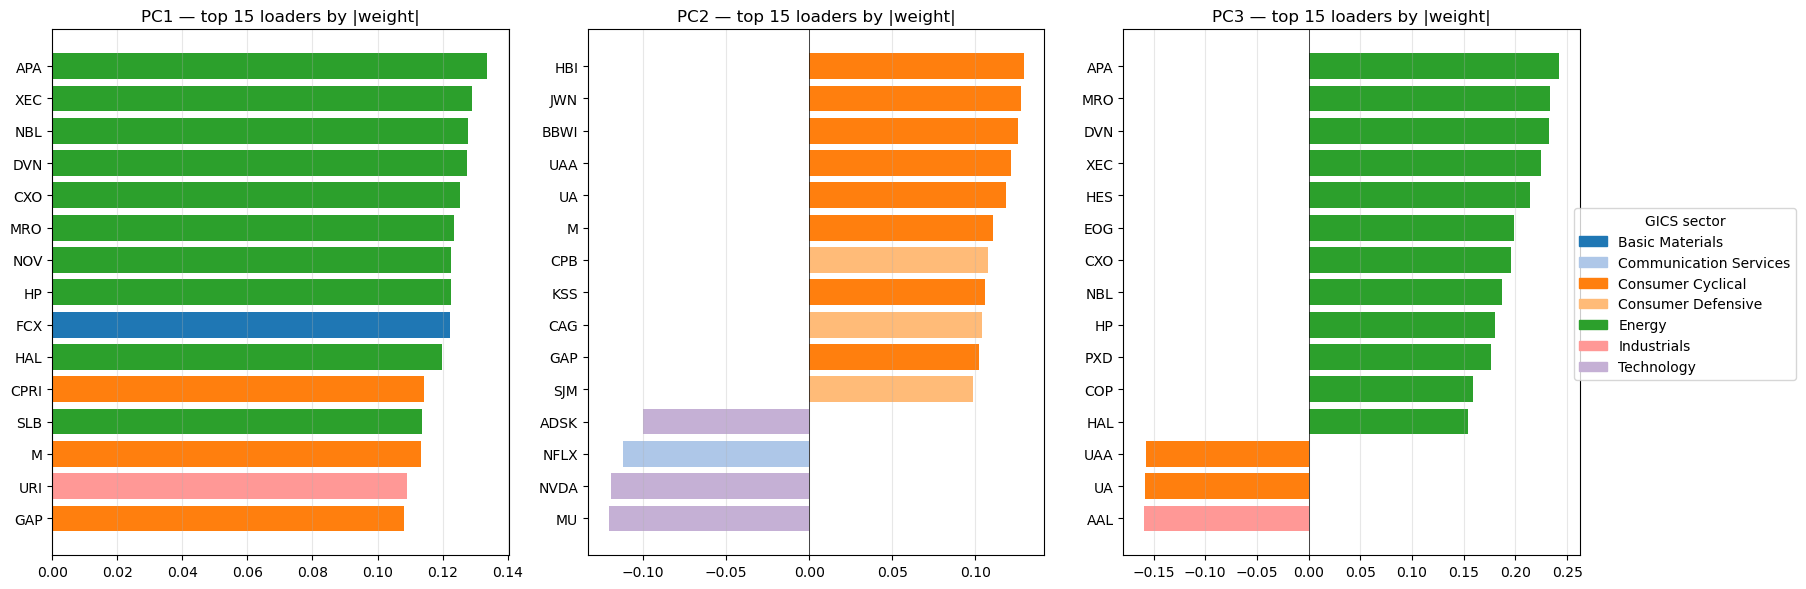

In [25]:
cols = sample.columns
keep = ~cols.duplicated()
unique_cols = cols[keep]

unique_sectors = sorted(set(ticker_sector.values()))
sector_palette = {s: plt.cm.tab20.colors[i % 20] for i, s in enumerate(unique_sectors)}

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
sectors_shown = set()
for ax, pc_idx, pc_name in zip(axes, [0, 1, 2], ["PC1", "PC2", "PC3"]):
    comp = pca.components_[pc_idx][keep]
    series = pd.Series(comp, index=unique_cols)
    top = series.reindex(series.abs().nlargest(15).index).sort_values()
    colors = [sector_palette.get(ticker_sector.get(t, "?"), "gray") for t in top.index]
    ax.barh(top.index, top.values, color=colors)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_title(f"{pc_name} — top 15 loaders by |weight|")
    ax.grid(alpha=0.3, axis="x")
    for t in top.index:
        sectors_shown.add(ticker_sector.get(t, "?"))

handles = [Patch(color=sector_palette[s], label=s) for s in sorted(sectors_shown)]
fig.legend(handles=handles, loc="center right", bbox_to_anchor=(1.13, 0.5),
            title="GICS sector")
fig.tight_layout()
plt.show()


### Persist Q1 to the database

Q1 is going to be the input to many downstream notebooks (clustering, portfolio construction, etc.). Saving it once with the right metadata (β window, shift, benchmark) means every downstream consumer reads exactly the same panel.


In [26]:
returns_lib = ac.get_library("returns_lib", create_if_missing=True)
returns_lib.write("returns_capm_residual", returns_capm_residual, metadata={
    "transformation": "log(C_t/C_{t-1}) - beta_{i,t} · log(SPY_t/SPY_{t-1})",
    "beta_window": 252,
    "beta_shift": 1,
    "benchmark": "SPY",
    "membership_masked": True,
    "fetched": pd.Timestamp.now(),
})
print("persisted returns_lib['returns_capm_residual']")


persisted returns_lib['returns_capm_residual']


## 9. Building Q2, go one level deeper and strip the sector signal

The PCA on Q1 told me the dominant remaining factor was Energy. That's an artifact of the dataset, not interesting structure I want clusters to find. To get rid of it, I residualize each stock against *its own sector ETF* instead of against SPY:

- AAPL (Technology) → subtract β × XLK
- XOM (Energy) → subtract β × XLE
- JPM (Financial Services) → subtract β × XLF
- etc.

This is the same rolling-252-day β trick as Q1, just with a different benchmark per stock. The result is **Q2, sector-β residual returns**: what's left after both the market and the sector are stripped out. Pure idiosyncratic behavior.

First, I build the ticker → sector ETF lookup.


In [27]:
SECTOR_TO_ETF = {
    "Technology":              "XLK",
    "Financial Services":      "XLF",
    "Healthcare":              "XLV",
    "Energy":                  "XLE",
    "Industrials":             "XLI",
    "Consumer Cyclical":       "XLY",
    "Consumer Defensive":      "XLP",
    "Basic Materials":         "XLB",
    "Utilities":               "XLU",
    "Real Estate":             "XLRE",
    "Communication Services":  "XLC",
}

ticker_to_etf = {}
unmapped = []
for lib in (stocks_lib, removed_lib):
    for sym in lib.list_symbols():
        meta = lib.read_metadata(sym).metadata or {}
        sector = meta.get("sector")
        etf = SECTOR_TO_ETF.get(sector)
        if etf:
            ticker_to_etf[sym] = etf
        else:
            unmapped.append((sym, sector))

print(f"mapped {len(ticker_to_etf)} tickers; unmapped {len(unmapped)}")
print("ETF coverage:")
for etf, n in sorted(Counter(ticker_to_etf.values()).items()):
    print(f"  {etf}: {n}")
if unmapped:
    print(f"first 5 unmapped: {unmapped[:5]}")


mapped 1084 tickers; unmapped 0
ETF coverage:
  XLB: 67
  XLC: 65
  XLE: 71
  XLF: 144
  XLI: 130
  XLK: 174
  XLP: 79
  XLRE: 43
  XLU: 60
  XLV: 120
  XLY: 131


### The Q2 residual function

Same math as the Q1 (CAPM-residual) function, just with a different benchmark per stock. I group tickers by their sector ETF and compute the rolling β per group in one vectorized rolling op, way faster than looping per ticker.


In [28]:
def build_sector_beta_residual_returns(prices, sector_etf_prices, ticker_to_etf, window=252):
    log_ret = np.log(prices / prices.shift(1))
    etf_log_ret = np.log(sector_etf_prices / sector_etf_prices.shift(1)).reindex(log_ret.index)

    etf_to_tickers = defaultdict(list)
    for ticker, etf in ticker_to_etf.items():
        if ticker in log_ret.columns and etf in etf_log_ret.columns:
            etf_to_tickers[etf].append(ticker)

    pieces = []
    for etf, tickers in tqdm(etf_to_tickers.items(), desc="sector-beta"):
        sub   = log_ret[tickers]
        bench = etf_log_ret[etf]
        cov   = sub.rolling(window).cov(bench)
        var   = bench.rolling(window).var()
        beta  = cov.div(var, axis=0).shift(1)
        pieces.append(sub - beta.mul(bench, axis=0))

    return pd.concat(pieces, axis=1)


### Loading the sector ETFs and building Q2

Pull all 11 sector ETFs into one DataFrame, then build the residual panel. Note the print of ETF first-available dates: XLRE only goes back to 2015, XLC only to 2018. That's going to cause a coverage gap that I'll need to deal with, but more on that below.


In [29]:
sector_etfs = sorted(set(SECTOR_TO_ETF.values()))
sector_etf_prices = pd.concat(
    [etf_lib.read(s).data["closeadj"].rename(s) for s in sector_etfs],
    axis=1,
).sort_index()

print("ETF first available dates:")
for c in sector_etf_prices.columns:
    first = sector_etf_prices[c].first_valid_index()
    print(f"  {c}: {first.date() if first else 'NONE'}")

returns_sector_beta_residual = build_sector_beta_residual_returns(
    prices, sector_etf_prices, ticker_to_etf
)

print(f"\nshape: {returns_sector_beta_residual.shape}")
print(f"median non-null per row: "
      f"{returns_sector_beta_residual.notna().sum(axis=1).median():.0f}")
print("\n2020-03-16 (COVID dip) describe:")
print(returns_sector_beta_residual.loc["2020-03-16"].describe())


ETF first available dates:
  XLB: 2000-01-03
  XLC: 2018-06-19
  XLE: 2000-01-03
  XLF: 2000-01-03
  XLI: 2000-01-03
  XLK: 2000-01-03
  XLP: 2000-01-03
  XLRE: 2015-10-08
  XLU: 2000-01-03
  XLV: 2000-01-03
  XLY: 2000-01-03


sector-beta:   0%|          | 0/11 [00:00<?, ?it/s]

sector-beta:  27%|██▋       | 3/11 [00:00<00:00, 24.01it/s]

sector-beta:  64%|██████▎   | 7/11 [00:00<00:00, 30.56it/s]

sector-beta: 100%|██████████| 11/11 [00:00<00:00, 36.32it/s]


shape: (6569, 1084)
median non-null per row: 447

2020-03-16 (COVID dip) describe:
count    485.000000
mean      -0.006261
std        0.061500
min       -0.202390
25%       -0.042290
50%       -0.006601
75%        0.031250
max        0.281326
Name: 2020-03-16 00:00:00, dtype: float64


### Does Q2 work? Per-sector validation

For Q1 I checked `corr(PC1, SPY) ≈ 0`. The analogous Q2 test, run per sector: within each sector's residual sub-panel, PC1 should be uncorrelated with that sector's own ETF return. If Q2's sector hedging worked, the dominant residual eigenvector inside each sector should no longer track the sector benchmark.


In [30]:
sample = returns_sector_beta_residual.loc["2018":"2019"].dropna(axis=1, how="all")
etf_sample_ret = np.log(sector_etf_prices / sector_etf_prices.shift(1)).loc[sample.index]

print(f"{'sector':<22} {'ETF':<6} {'n':>5}  corr(PC1, ETF)")
print("-" * 55)
for sector, etf in sorted(SECTOR_TO_ETF.items(), key=lambda x: x[1]):
    members = [t for t, e in ticker_to_etf.items() if e == etf and t in sample.columns]
    sub = sample[members].dropna(axis=1, how="all").fillna(0)
    if sub.shape[1] < 2:
        continue
    pc1 = PCA(n_components=1).fit_transform(sub).flatten()
    etf_ret = etf_sample_ret[etf].reindex(sample.index)
    valid = etf_ret.notna()
    if valid.sum() < 30:
        print(f"{sector:<22} {etf:<6} {sub.shape[1]:>5}  (insufficient ETF history)")
        continue
    corr = np.corrcoef(pc1[valid], etf_ret[valid])[0, 1]
    print(f"{sector:<22} {etf:<6} {sub.shape[1]:>5}  {corr:>+0.3f}")


sector                 ETF        n  corr(PC1, ETF)
-------------------------------------------------------
Basic Materials        XLB       25  +0.046
Communication Services XLC       23  +0.092
Energy                 XLE       34  +0.012
Financial Services     XLF       75  +0.032
Industrials            XLI       75  +0.045
Technology             XLK       64  +0.014
Consumer Defensive     XLP       38  +0.004
Real Estate            XLRE      33  -0.093
Utilities              XLU       29  +0.078
Healthcare             XLV       65  -0.046
Consumer Cyclical      XLY       63  +0.030


### And the same check over time, per sector

Same test as the Q1 rolling validation, but now I do it per sector. One small-multiples panel per sector. A red dotted band at ±0.10 marks the "basically zero" zone. Most sectors should hover inside it.


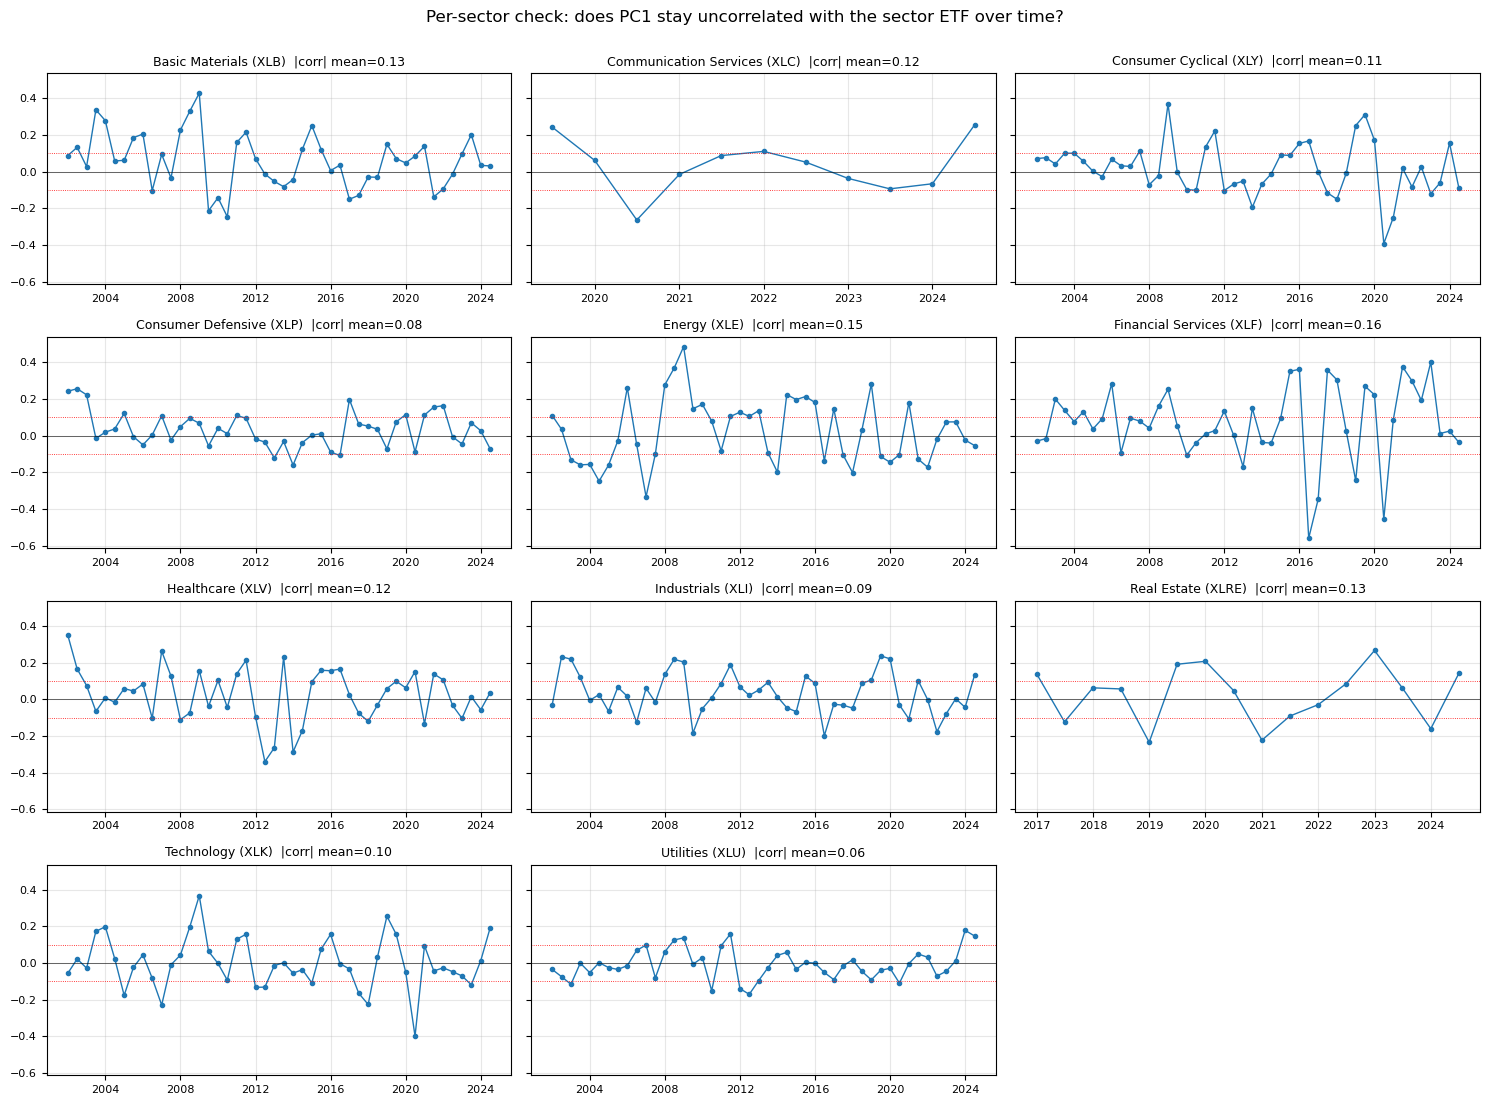

In [31]:
etf_log_ret_full = np.log(sector_etf_prices / sector_etf_prices.shift(1))
q2_rolling = defaultdict(list)

for w_start in windows:
    w_end = w_start + pd.DateOffset(years=1)
    sub_q2 = returns_sector_beta_residual.loc[w_start:w_end]
    sub_q2 = sub_q2.loc[:, ~sub_q2.columns.duplicated()]
    for sector, etf in SECTOR_TO_ETF.items():
        members = [t for t, e in ticker_to_etf.items() if e == etf and t in sub_q2.columns]
        sub = sub_q2[members].dropna(axis=1, thresh=200).fillna(0)
        if sub.shape[1] < 5:
            continue
        etf_w = etf_log_ret_full[etf].reindex(sub.index)
        valid = etf_w.notna()
        if valid.sum() < 50:
            continue
        pc1 = PCA(n_components=1).fit_transform(sub).flatten()
        corr = np.corrcoef(pc1[valid], etf_w[valid])[0, 1]
        q2_rolling[sector].append({"window_start": w_start, "corr": corr, "n": sub.shape[1]})

fig, axes = plt.subplots(4, 3, figsize=(15, 11), sharey=True)
for ax, (sector, etf) in zip(axes.flatten(), sorted(SECTOR_TO_ETF.items())):
    recs = q2_rolling.get(sector, [])
    if not recs:
        ax.set_visible(False); continue
    df = pd.DataFrame(recs)
    ax.plot(df["window_start"], df["corr"], marker="o", lw=1, ms=3)
    ax.axhline(0,    color="black", lw=0.4)
    ax.axhline(0.10, color="red",   ls=":", lw=0.6)
    ax.axhline(-0.10, color="red",  ls=":", lw=0.6)
    ax.set_title(f"{sector} ({etf})  |corr| mean={np.mean(np.abs(df['corr'])):.2f}",
                  fontsize=9)
    ax.tick_params(labelsize=8); ax.grid(alpha=0.3)
if len(SECTOR_TO_ETF) < axes.size:
    for ax in axes.flatten()[len(SECTOR_TO_ETF):]:
        ax.set_visible(False)
fig.suptitle("Per-sector check: does PC1 stay uncorrelated with the sector ETF over time?", y=1.00)
fig.tight_layout()
plt.show()


**What I see in the small-multiples.** Most sectors hover inside ±0.20 most of the time, which is fine. Two exceptions: **Financial Services** and **Energy** both spike past ±0.4 during 2008-09 (the GFC), and Energy spikes again around 2014-15 (the oil crash). Same story as Q1's rolling validation, the static β can't keep up with regime shifts in stressed periods.

**Comm Services and Real Estate** have visibly shorter records because XLRE and XLC have late inception dates. Which brings me to the next gotcha.


### A problem: XLRE didn't exist before 2015, XLC before 2018

The XLRE ETF (Real Estate) was launched in October 2015. XLC (Communication Services) was launched in June 2018. For stocks in those sectors, I literally can't compute Q2 before the ETF existed, there's no benchmark to subtract.

Adding the 252-day β warm-up, Real Estate stocks have no Q2 residuals before roughly **October 2016**, and Comm Services stocks have none before roughly **June 2019**. The plot below shows the count of valid Q2 residuals per sector over time, and you can clearly see those two sectors come online late.

For the downstream clustering / portfolio work, the simplest fix is to just drop those tickers from the early-period analysis.


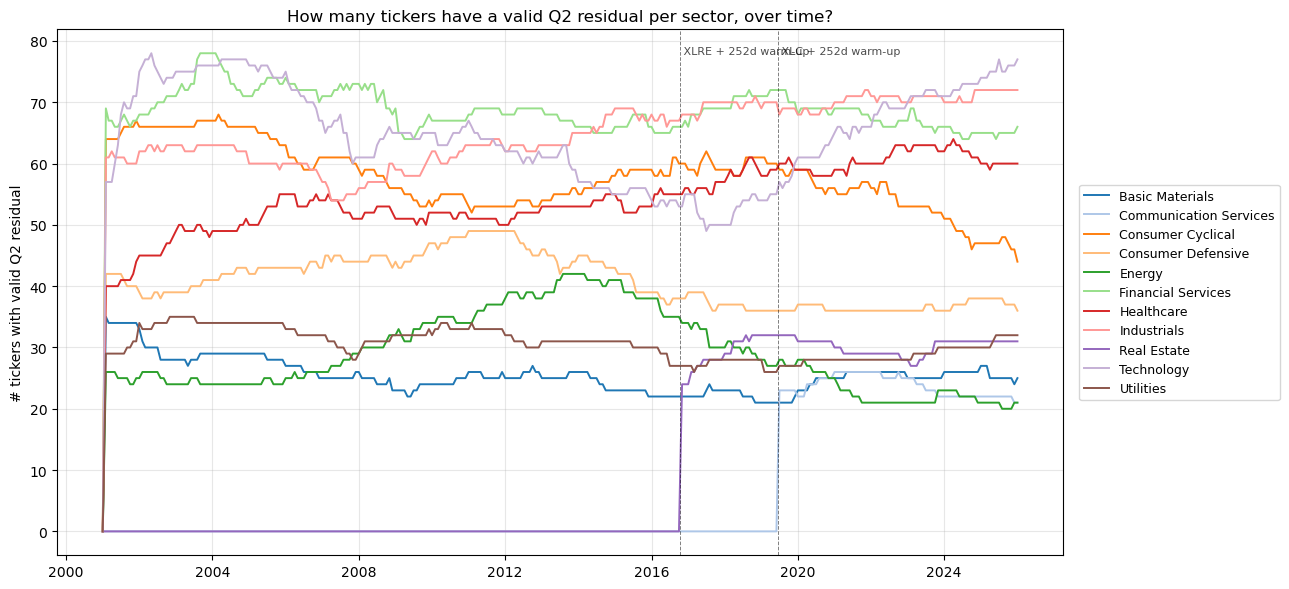

In [32]:
cov_dates = pd.date_range("2001-01-01", "2026-01-01", freq="MS")
cov_records = []
for d in cov_dates:
    row = {"date": d}
    asof = returns_sector_beta_residual.index.asof(d)
    for sector, etf in SECTOR_TO_ETF.items():
        members = [t for t, e in ticker_to_etf.items()
                    if e == etf and t in returns_sector_beta_residual.columns]
        if not members or pd.isna(asof):
            row[sector] = 0
        else:
            row[sector] = int(returns_sector_beta_residual.loc[asof, members].notna().sum())
    cov_records.append(row)
coverage_df = pd.DataFrame(cov_records).set_index("date")

fig, ax = plt.subplots(figsize=(13, 6))
sector_order = sorted(SECTOR_TO_ETF.keys())
colors = plt.cm.tab20.colors
for i, sector in enumerate(sector_order):
    ax.plot(coverage_df.index, coverage_df[sector], lw=1.4, label=sector, color=colors[i % 20])
ax.set_title("How many tickers have a valid Q2 residual per sector, over time?")
ax.set_ylabel("# tickers with valid Q2 residual")
ax.axvline(pd.Timestamp("2016-10-08"), color="black", ls="--", lw=0.7, alpha=0.5)
ax.text(pd.Timestamp("2016-10-08"), ax.get_ylim()[1] * 0.95,
        " XLRE + 252d warm-up", fontsize=8, alpha=0.7)
ax.axvline(pd.Timestamp("2019-06-19"), color="black", ls="--", lw=0.7, alpha=0.5)
ax.text(pd.Timestamp("2019-06-19"), ax.get_ylim()[1] * 0.95,
        " XLC + 252d warm-up", fontsize=8, alpha=0.7)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


### Persist Q2 to the database

Same as Q1 above, save with the metadata that records exactly how it was built so downstream consumers can read it unambiguously.


In [33]:
returns_lib.write("returns_sector_beta_residual", returns_sector_beta_residual, metadata={
    "transformation": "log(C_t/C_{t-1}) - beta_{i,t} · log(sector_etf_t/sector_etf_{t-1})",
    "beta_window": 252,
    "beta_shift": 1,
    "benchmark": "GICS sector ETF (XL*)",
    "sector_to_etf": SECTOR_TO_ETF,
    "membership_masked": True,
    "fetched": pd.Timestamp.now(),
})
print("persisted returns_lib['returns_sector_beta_residual']")


persisted returns_lib['returns_sector_beta_residual']


## 10. Q1 vs Q2: was the extra work worth it?

Both panels pass their individual sanity checks. The real question now is whether Q2 actually gives me a *meaningfully different* (and ideally cleaner) view of the data. Two diagnostics:

1. **PC spectrum + MP survivor count.** If Q2 is doing more work, top eigenvalues should shrink (less concentrated factors) and more PCs should survive the noise cut (more "real" structure to look at).
2. **Top-PC sector composition.** Q1's PC1 and PC3 were dominated by Energy. If Q2's sector-β actually strips sector exposure, those Energy-heavy PCs should disappear from Q2.


In [34]:
q1 = returns_capm_residual.loc["2018":"2019"]
q1 = q1.loc[:, ~q1.columns.duplicated()]
q2 = returns_sector_beta_residual.loc["2018":"2019"]
q2 = q2.loc[:, ~q2.columns.duplicated()]
common = sorted(set(q1.dropna(axis=1).columns) & set(q2.dropna(axis=1).columns))
q1c = q1[common].fillna(0)
q2c = q2[common].fillna(0)

T, N = q1c.shape
mp_floor = ((1 + np.sqrt(N / T)) ** 2) / N
pca1 = PCA(n_components=50).fit(q1c)
pca2 = PCA(n_components=50).fit(q2c)
r1, r2 = pca1.explained_variance_ratio_, pca2.explained_variance_ratio_

print(f"Sample T × N: {T} × {N}    MP floor: {mp_floor:.4f}")
print(f"Q1 PCs above MP: {(r1 > mp_floor).sum():>3} / 50   "
      f"(sum: {r1[r1 > mp_floor].sum():.3f})")
print(f"Q2 PCs above MP: {(r2 > mp_floor).sum():>3} / 50   "
      f"(sum: {r2[r2 > mp_floor].sum():.3f})")
print(f"Total top-50 var: Q1 = {r1.sum():.3f}    Q2 = {r2.sum():.3f}")

print(f"\n{'PC':>4}    {'Q1_var':>8}    {'Q2_var':>8}    {'Δ (Q2-Q1)':>10}")
print("-" * 42)
for i in range(15):
    print(f"{i+1:>4}    {r1[i]:>8.4f}    {r2[i]:>8.4f}    {r2[i] - r1[i]:>+10.4f}")

print("\n" + "-" * 70)
print("Sector composition of top-10 loaders per PC")
print("-" * 70)
for pc_idx in range(3):
    l1 = pd.Series(pca1.components_[pc_idx], index=q1c.columns)
    l2 = pd.Series(pca2.components_[pc_idx], index=q2c.columns)
    top_q1 = l1.abs().nlargest(10).index
    top_q2 = l2.abs().nlargest(10).index
    sect_q1 = Counter(ticker_sector.get(t, "?") for t in top_q1)
    sect_q2 = Counter(ticker_sector.get(t, "?") for t in top_q2)
    print(f"\nPC{pc_idx+1}:")
    print(f"  Q1 top-10 sectors: {dict(sect_q1.most_common())}")
    print(f"  Q2 top-10 sectors: {dict(sect_q2.most_common())}")


Sample T × N: 503 × 414    MP floor: 0.0088
Q1 PCs above MP:  21 / 50   (sum: 0.428)
Q2 PCs above MP:  25 / 50   (sum: 0.394)
Total top-50 var: Q1 = 0.615    Q2 = 0.565

  PC      Q1_var      Q2_var     Δ (Q2-Q1)
------------------------------------------
   1      0.0874      0.0608       -0.0266
   2      0.0451      0.0301       -0.0150
   3      0.0400      0.0249       -0.0150
   4      0.0295      0.0231       -0.0063
   5      0.0269      0.0197       -0.0073
   6      0.0206      0.0169       -0.0038
   7      0.0184      0.0167       -0.0017
   8      0.0158      0.0148       -0.0009
   9      0.0149      0.0144       -0.0005
  10      0.0140      0.0130       -0.0010
  11      0.0127      0.0128       +0.0001
  12      0.0121      0.0123       +0.0002
  13      0.0112      0.0123       +0.0011
  14      0.0109      0.0118       +0.0009
  15      0.0106      0.0115       +0.0009

----------------------------------------------------------------------
Sector composition of top-1

### Visualizing the correlation matrices: raw → Q1 → Q2

Three heatmaps side by side on the 2018-2019 sample, with tickers grouped by sector (so stocks in the same sector are adjacent on both axes):

- **Raw log returns**: everything correlates with everything else, mean off-diagonal correlation around 0.30. The whole matrix is uniformly red because the market signal dominates.
- **Q1 (CAPM residual)**: most of the red is gone, mean off-diagonal correlation drops to ~0.09. What remains is a diagonal block pattern: sector-internal correlations that the market subtraction couldn't remove.
- **Q2 (sector-β residual)**: those sector blocks dissolve too. Mean off-diagonal correlation falls further to ~0.06. What's left is mostly noise plus a faint residual structure (XLE doesn't perfectly span every energy stock, so there's still a tiny Energy block).

This single picture summarizes the entire pipeline visually.


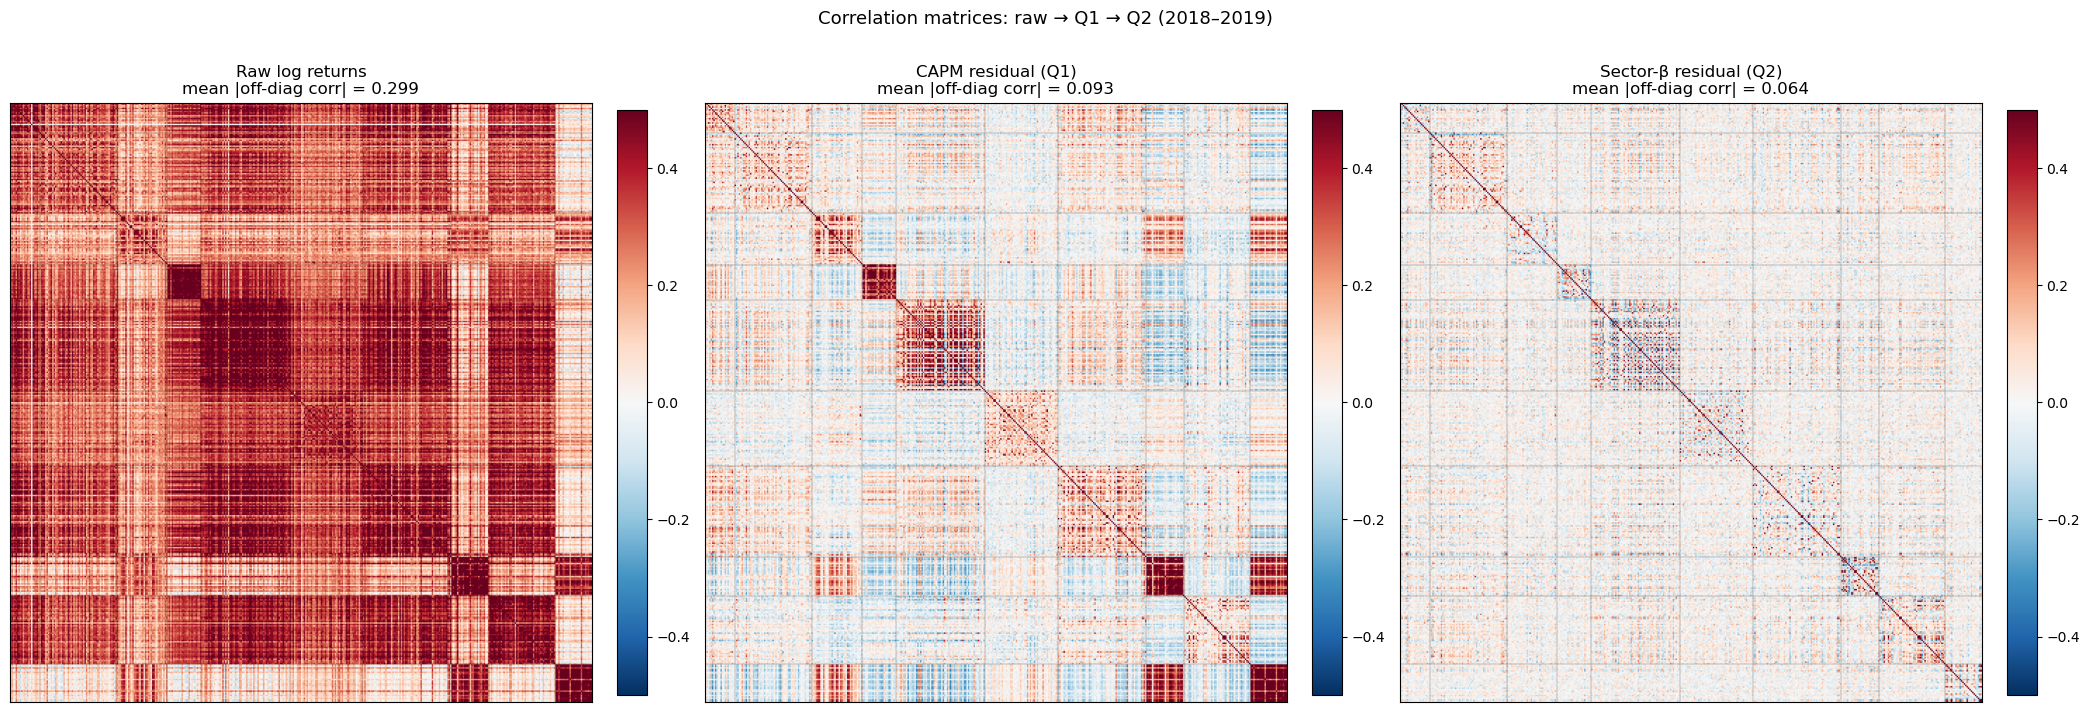

In [35]:
log_ret_panel = np.log(prices / prices.shift(1))
log_ret_panel = log_ret_panel.loc[:, ~log_ret_panel.columns.duplicated()]
q1_dd = returns_capm_residual.loc[:, ~returns_capm_residual.columns.duplicated()]
q2_dd = returns_sector_beta_residual.loc[:, ~returns_sector_beta_residual.columns.duplicated()]

window = slice("2018", "2019")
common3 = sorted(
    set(log_ret_panel.loc[window].dropna(axis=1).columns) &
    set(q1_dd.loc[window].dropna(axis=1).columns) &
    set(q2_dd.loc[window].dropna(axis=1).columns)
)
common3_sorted = sorted(common3, key=lambda t: (ticker_sector.get(t, "?"), t))

panels = {
    "Raw log returns":           log_ret_panel.loc[window, common3_sorted].fillna(0),
    "CAPM residual (Q1)":        q1_dd.loc[window, common3_sorted].fillna(0),
    "Sector-β residual (Q2)":    q2_dd.loc[window, common3_sorted].fillna(0),
}

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, (title, df) in zip(axes, panels.items()):
    corr = df.corr()
    off_diag_mean = np.abs(corr.values - np.eye(len(corr))).sum() / (len(corr) * (len(corr) - 1))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-0.5, vmax=0.5, aspect="auto")
    ax.set_title(f"{title}\nmean |off-diag corr| = {off_diag_mean:.3f}")
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

sectors_list = [ticker_sector.get(t, "?") for t in common3_sorted]
boundaries = [i for i in range(1, len(sectors_list)) if sectors_list[i] != sectors_list[i-1]]
for ax in axes:
    for b in boundaries:
        ax.axhline(b - 0.5, color="black", lw=0.3, alpha=0.5)
        ax.axvline(b - 0.5, color="black", lw=0.3, alpha=0.5)
fig.suptitle("Correlation matrices: raw → Q1 → Q2 (2018–2019)", y=1.01, fontsize=13)
fig.tight_layout()
plt.show()


### Side-by-side PC spectrum

Same idea as the Q1-only spectrum from earlier, but Q1 and Q2 bars next to each other so I can see directly how the eigenvalues differ. Red dashed line is the same MP noise floor.


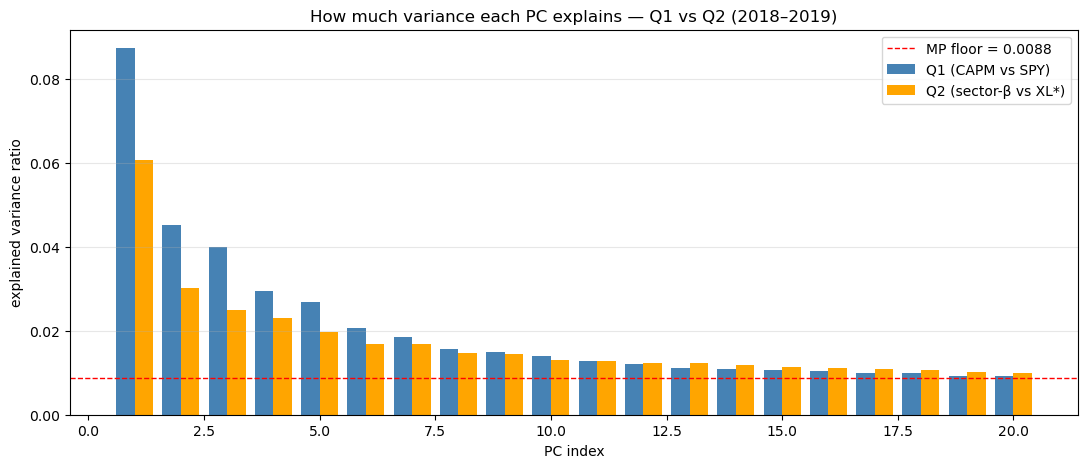

In [36]:
plt.figure(figsize=(13, 5))
x = np.arange(1, 21); w = 0.4
plt.bar(x - w/2, r1[:20], width=w, label="Q1 (CAPM vs SPY)",      color="steelblue")
plt.bar(x + w/2, r2[:20], width=w, label="Q2 (sector-β vs XL*)",  color="orange")
plt.axhline(mp_floor, color="red", lw=1, ls="--",
            label=f"MP floor = {mp_floor:.4f}")
plt.title("How much variance each PC explains — Q1 vs Q2 (2018–2019)")
plt.xlabel("PC index"); plt.ylabel("explained variance ratio")
plt.legend(); plt.grid(alpha=0.3, axis="y")
plt.show()


## 11. How many "real" factors are in the data, over time?

So far I've computed the MP survivor count on one fixed window (2018-2019). But the count *changes* over time, and the way it changes is itself informative. There's a known result (Avellaneda 2010) that the number of significant eigenvalues drops during crises, because correlations spike and most of the variance gets compressed onto fewer factors.

Let me compute the MP survivor count on a rolling 1-year window every month, on Q2. The plot below has crisis markers (dot-com fallout, GFC, EU debt, oil crash, COVID, 2022 rates shock), I expect to see clear dips at each one.


288 monthly windows; survivor count mean=16.9, min=11, max=20


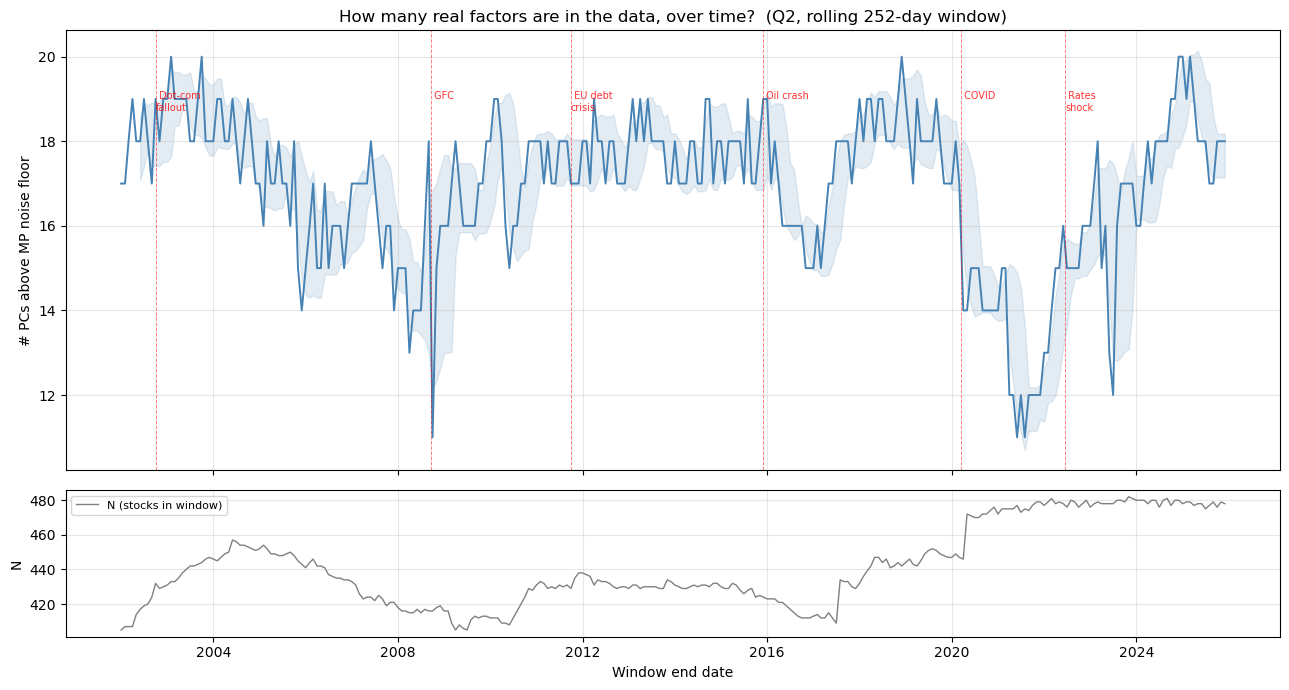

In [37]:
rebal_dates = pd.date_range("2002-01-01", "2025-12-01", freq="MS")
mp_records = []
for d in rebal_dates:
    train = returns_sector_beta_residual.loc[d - pd.DateOffset(years=1):d]
    train = train.loc[:, ~train.columns.duplicated()].dropna(axis=1, thresh=200).fillna(0)
    if train.shape[1] < 50:
        continue
    T_, N_ = train.shape
    pca_f = PCA(n_components=min(N_, 100)).fit(train)
    mp_floor_d = ((1 + np.sqrt(N_ / T_)) ** 2) / N_
    survivors = (pca_f.explained_variance_ratio_ > mp_floor_d).sum()
    mp_records.append({"date": d, "survivors": survivors,
                        "N": N_, "T": T_, "mp_floor": mp_floor_d})

mp_ts = pd.DataFrame(mp_records)
print(f"{len(mp_ts)} monthly windows; survivor count "
      f"mean={mp_ts['survivors'].mean():.1f}, "
      f"min={mp_ts['survivors'].min()}, max={mp_ts['survivors'].max()}")

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True,
                          gridspec_kw={"height_ratios": [3, 1]})
axes[0].plot(mp_ts["date"], mp_ts["survivors"], color="steelblue", lw=1.4)
axes[0].fill_between(mp_ts["date"],
                      mp_ts["survivors"].rolling(6).mean() - mp_ts["survivors"].rolling(6).std(),
                      mp_ts["survivors"].rolling(6).mean() + mp_ts["survivors"].rolling(6).std(),
                      color="steelblue", alpha=0.15)
for label, x in [("Dot-com\nfallout", "2002-10-01"), ("GFC", "2008-09-15"),
                  ("EU debt\ncrisis", "2011-10-01"), ("Oil crash", "2015-12-01"),
                  ("COVID", "2020-03-15"), ("Rates\nshock", "2022-06-15")]:
    axes[0].axvline(pd.Timestamp(x), color="red", ls="--", lw=0.7, alpha=0.5)
    axes[0].text(pd.Timestamp(x), axes[0].get_ylim()[1] * 0.93, " " + label,
                  fontsize=7, color="red", alpha=0.8, va="top")
axes[0].set_title("How many real factors are in the data, over time?  (Q2, rolling 252-day window)")
axes[0].set_ylabel("# PCs above MP noise floor"); axes[0].grid(alpha=0.3)

axes[1].plot(mp_ts["date"], mp_ts["N"], color="gray", lw=1, label="N (stocks in window)")
axes[1].set_ylabel("N"); axes[1].legend(loc="upper left", fontsize=8)
axes[1].grid(alpha=0.3); axes[1].set_xlabel("Window end date")
fig.tight_layout()
plt.show()


**Reading the plot.** Baseline is around 17-18 surviving factors. There are clear dips during the GFC (down to 14), the COVID crash + aftermath (down to 11-14 for an unusually long stretch through 2022), and a partial recovery by 2023. The bottom panel shows N (the number of stocks in the window) rising over time as the index grows, the survivor-count dips are *not* mechanical artifacts of N changing.

This is the Avellaneda prediction confirmed on my data: during stress periods, cross-sectional correlations spike, the signal eigenvalues concentrate, and the noise floor takes a bigger bite out of the spectrum. Conceptually it means: in calm times, there are ~17 distinct factors driving the cross-section; in crises, those collapse to maybe 11. Diversification opportunities shrink.
